In [2]:
%pip install -q pandas tensorflow numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


# Deep Learning for Function Estimation
### Amir, 2025, NUS SoC ACE

#### We'll try to estimate the quality of red wine samples based on their physical and chemical features
#### We compute and report the mean absolute error, MAE

In [3]:
# CNN version
# Regression Example With wine dataset ...
import pandas as pd
from pandas import read_csv
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense , Dropout
from tensorflow.keras.layers import Conv1D
from tensorflow.keras.layers import MaxPooling1D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt


In [4]:
# mounting the Google drive
# from google.colab import drive

# drive.mount('/content/drive')

# # Load the dataset
# fp = "/content/drive/My Drive/emeritus/2025/Module2-3/wine_r2_t_noheader.csv"
fp = "wine_r2_t_noheader.csv"

In [5]:

# load dataset to a Pandas dataframe
dataframe = read_csv(fp , header=None)
# copy only values to a numpy n dimensional array, ndarray
dataset = dataframe.values

# split into input (X) and output (Y) variables
X = dataset[:,0:11]
Y = dataset[:,11]

print(X.shape)
X = X.reshape(X.shape[0], X.shape[1], 1)
print(X.shape)


(1599, 11)
(1599, 11, 1)


In [6]:
print(type(dataset))
print(dataset.shape)
print(dataframe.describe())
print( dataframe.head() )

<class 'numpy.ndarray'>
(1599, 12)
                0            1            2            3            4   \
count  1599.000000  1599.000000  1599.000000  1599.000000  1599.000000   
mean      8.319637     0.527821     0.270976     2.538806     0.087467   
std       1.741096     0.179060     0.194801     1.409928     0.047065   
min       4.600000     0.120000     0.000000     0.900000     0.012000   
25%       7.100000     0.390000     0.090000     1.900000     0.070000   
50%       7.900000     0.520000     0.260000     2.200000     0.079000   
75%       9.200000     0.640000     0.420000     2.600000     0.090000   
max      15.900000     1.580000     1.000000    15.500000     0.611000   

                5            6            7            8            9   \
count  1599.000000  1599.000000  1599.000000  1599.000000  1599.000000   
mean     15.874922    46.467792     0.996747     3.311113     0.658149   
std      10.460157    32.895324     0.001887     0.154386     0.169507   
mi

In [7]:
# define base model, a deep covolutional one
# structure comprisses 2 1d convolution layers with 16 and 12 filters, filters are 3x1
# then maxpooling for downsampling, a fully connected dense layer with 12 neurons
# Droput layer with 20% at the end
#
def baseline_model():
    # create model
    model = Sequential()
    model.add(Conv1D(16, 3, activation="relu", input_shape=(11,1)))
    model.add(Conv1D(12, 3, activation="relu"))
    model.add(MaxPooling1D())
    model.add(Flatten())
    model.add(Dense(12, input_dim=8, kernel_initializer='normal', activation='relu'))
    model.add( Dropout(0.2) )
    model.add(Dense(1, kernel_initializer='normal'))
    # Compile model
    model.compile(loss='mean_squared_error', optimizer='adam')
    return model


In [8]:
# splitting the train and test subsets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

In [19]:
# training the model for 900 epochs and testing the trained model with the training data
# we report the training error
estimator = baseline_model()
estimator.fit(X_train, Y_train, epochs=900, verbose=2)
prediction = estimator.predict(X_train)

train_error =  np.abs(Y_train - prediction)
mean_error = np.mean(train_error)
min_error = np.min(train_error)
max_error = np.max(train_error)
std_error = np.std(train_error)
# print('\nTraining results:\nmean=',mean_error,'\nmin=',min_error,'\nmax=',max_error,'\nstd=',std_error)

print('\nTraining results:')
print('MAE =', mean_error)
print('Min error =', min_error)
print('Max error =', max_error)
print('STD error =', std_error)

Epoch 1/900


/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


40/40 - 0s - 8ms/step - loss: 17.2572
Epoch 2/900
40/40 - 0s - 870us/step - loss: 10.2974
Epoch 3/900
40/40 - 0s - 728us/step - loss: 9.6460
Epoch 4/900
40/40 - 0s - 758us/step - loss: 7.3620
Epoch 5/900
40/40 - 0s - 678us/step - loss: 4.7812
Epoch 6/900
40/40 - 0s - 668us/step - loss: 2.6909
Epoch 7/900
40/40 - 0s - 651us/step - loss: 2.1515
Epoch 8/900
40/40 - 0s - 643us/step - loss: 2.2362
Epoch 9/900
40/40 - 0s - 653us/step - loss: 2.0336
Epoch 10/900
40/40 - 0s - 641us/step - loss: 2.0992
Epoch 11/900
40/40 - 0s - 637us/step - loss: 2.0103
Epoch 12/900
40/40 - 0s - 626us/step - loss: 2.1629
Epoch 13/900
40/40 - 0s - 654us/step - loss: 2.0183
Epoch 14/900
40/40 - 0s - 656us/step - loss: 2.0311
Epoch 15/900
40/40 - 0s - 661us/step - loss: 2.0687
Epoch 16/900
40/40 - 0s - 641us/step - loss: 2.0829
Epoch 17/900
40/40 - 0s - 663us/step - loss: 1.8258
Epoch 18/900
40/40 - 0s - 640us/step - loss: 1.9352
Epoch 19/900
40/40 - 0s - 645us/step - loss: 2.0304
Epoch 20/900
40/40 - 0s - 645us/s

In [10]:
# showing the real and predicted quality scores for the training data
df = pd.DataFrame({'Actual': Y_train, 'Predicted': prediction.ravel() })
df1 = df.tail(25)
print(df1)

      Actual  Predicted
1254     6.0   5.520757
1255     6.0   5.338784
1256     5.0   5.170442
1257     5.0   5.582489
1258     6.0   5.213950
1259     5.0   5.407765
1260     5.0   5.575131
1261     5.0   5.571114
1262     6.0   5.623686
1263     6.0   6.327053
1264     5.0   5.475154
1265     5.0   5.778417
1266     5.0   5.214051
1267     4.0   5.144703
1268     5.0   5.651218
1269     6.0   5.249544
1270     6.0   5.835817
1271     6.0   5.927447
1272     6.0   5.555772
1273     5.0   5.180700
1274     5.0   5.154553
1275     5.0   5.133619
1276     6.0   5.239623
1277     6.0   5.706795
1278     5.0   5.133619


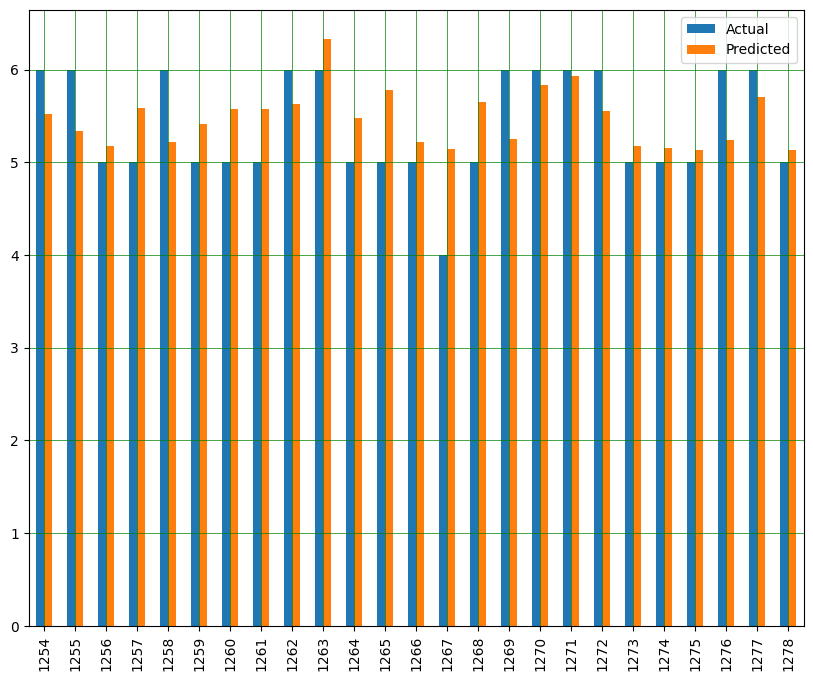

In [11]:
df1.plot(kind='bar',figsize=(10,8))
plt.grid(which='major', linestyle='-', linewidth='0.5', color='green')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.show()

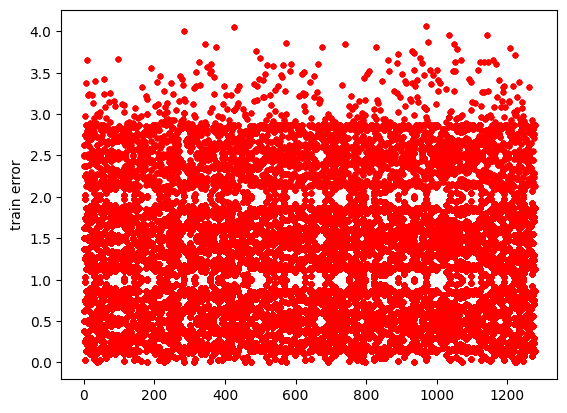

In [12]:
plt.plot(train_error,'r.')
plt.ylabel('train error')
plt.show()

In [15]:
# testing the model with the test data
prediction = estimator.predict(X_test)

test_error =  np.abs(Y_test - prediction)
mean_error = np.mean(test_error)
min_error = np.min(test_error)
max_error = np.max(test_error)
std_error = np.std(test_error)
print('\nTesting results:\nmean=',mean_error,'\nmin=',min_error,'\nmax=',max_error,'\nstd=',std_error)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 992us/step

Testing results:
mean= 0.6992704914975911 
min= 9.441375732421875e-05 
max= 4.0081610679626465 
std= 0.5157681714703469


In [16]:
# and showing the results
df = pd.DataFrame({'Actual': Y_test, 'Predicted': prediction.ravel() })
df1 = df.tail(25)
print(df1)

     Actual  Predicted
295     6.0   5.885284
296     6.0   5.817090
297     5.0   5.790968
298     6.0   5.316213
299     5.0   5.358256
300     6.0   5.514863
301     5.0   5.133619
302     6.0   5.554558
303     6.0   5.606656
304     6.0   5.468997
305     6.0   6.129179
306     5.0   5.247334
307     5.0   5.186764
308     6.0   5.428421
309     5.0   5.374425
310     5.0   5.561408
311     6.0   6.289496
312     5.0   5.642445
313     5.0   5.133619
314     5.0   5.402232
315     6.0   6.089696
316     4.0   6.101767
317     5.0   5.650958
318     4.0   5.280523
319     6.0   6.165509


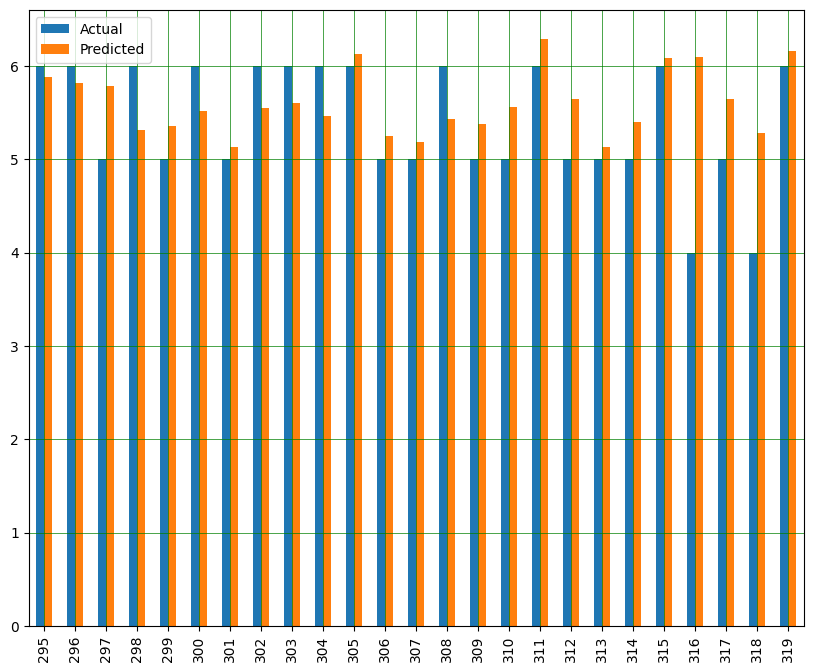

In [17]:
df1.plot(kind='bar',figsize=(10,8))
plt.grid(which='major', linestyle='-', linewidth='0.5', color='green')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.show()

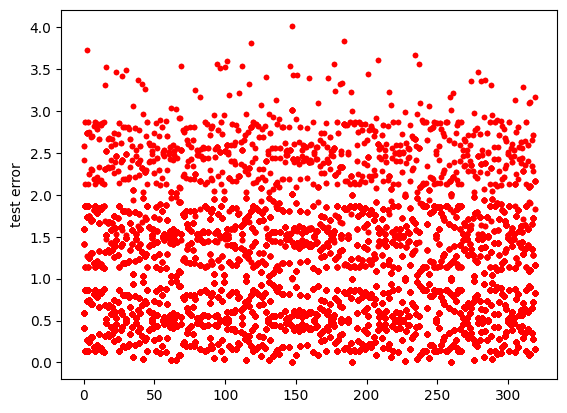

In [18]:
plt.plot(test_error,'r.')
plt.ylabel('test error')
plt.show()

##  Practices
1. train the model for 1400 epochs. what are the training and testing MAE?
2. repeat that with 6000 training epochs. what are the training and testing MAE?
3. move back to 900 training epochs. add two convolutional and one dense layer with the same features of the layers used. what are the training and testing MAE?
4. go for 6000 training epochs. Do you feel any overfitting?
5. set back everything to the original setting, then try to normalize the training and testing features and outputs using standard_scaler. Then see if anything gets better or not. You may use insttructions like what you can see in the next cell.  

#### points:
- use GPU as your runtime type
- if the notebook overflows, change the verbose to 0, e.g. verbose=0 in the training cell.

In [15]:
'''
# normalization
from sklearn.preprocessing import StandardScaler

# Create scalers
scaler_X = StandardScaler()
scaler_y = StandardScaler()

# Standardize X_train and X_test
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Standardize Y_train and Y_test (only if y is continuous, e.g., in regression)
y_train_scaled = scaler_y.fit_transform(Y_train.reshape(-1, 1))  # Reshape if needed
y_test_scaled = scaler_y.transform(Y_test.reshape(-1, 1))
'''

'\n# normalization\nfrom sklearn.preprocessing import StandardScaler\n\n# Create scalers\nscaler_X = StandardScaler()\nscaler_y = StandardScaler()\n\n# Standardize X_train and X_test\nX_train_scaled = scaler_X.fit_transform(X_train)\nX_test_scaled = scaler_X.transform(X_test)\n\n# Standardize Y_train and Y_test (only if y is continuous, e.g., in regression)\ny_train_scaled = scaler_y.fit_transform(Y_train.reshape(-1, 1))  # Reshape if needed\ny_test_scaled = scaler_y.transform(Y_test.reshape(-1, 1))\n'